# İç Denetimde Python, Pandas ve EDA — Uygulamalı Başlangıç

Eğitmen: Dr. Suat ATAN

https://verimlilikbulteni.substack.com/

https://suatatan.com/

<br>

Bu notebook, **İç Denetim Koordinatörlüğü** için planlanan iki günlük veri analitiği eğitiminin ilk uygulamalı bölümüdür.

Bu oturumun amacı Python sözdizimini ezberletmek değildir. Amaç, bir denetim sorusunu adım adım **veriye sorulabilir bir soruya** ve ardından **çalışan bir koda** çevirmektir.

> **Ana fikir:** Notebook = açıklama + kod + sonuç + yorum.
> Bir denetçi için bu yapı aynı zamanda yapılan analizin tekrar edilebilir ve gözden geçirilebilir olması demektir.

### Bu notebook kimin için?

Daha önce hiç kod yazmamış, ama Excel'de filtre, pivot tablo ve formül kullanan denetçiler için hazırlanmıştır. Her kod hücresinden önce **ne yapacağımızı**, önemli çıktılardan sonra da **sonucu nasıl okuyacağımızı** açıklıyoruz.

### Bu oturumda ilerleyeceğimiz yol

1. Notebook/Colab mantığı ve ilk Python kodu
2. Matematik, değişkenler, `if/else`, liste ve fonksiyon mantığı
3. Rastgele sayı üretimi
4. Kütüphane kavramı ve Pandas
5. Excel verisini Pandas'a alma
6. Kolonlar, özetleme, filtreleme ve toplu işlemler
7. Basit bir denetim risk skoru oluşturma
8. EDA ve aykırı değer (outlier) tespiti
9. RapidFuzz (FuzzyWuzzy mantığı) ile benzer isim arama
10. Hazır EDA araçları
11. Zaman kalırsa: duplicate ve sıra/gap kontrolleri

Eğitim programına göre bu notebook, **Python → Jupyter/Colab → Pandas → EDA** akışını kapsar. Outlier konusu ikinci günün anomali bölümüne, son bölümdeki küçük denetim testleri ise Benford/gap/network gibi daha ileri tekniklere geçiş sağlar.

### Eğitmen için yaklaşık tempo — 90–110 dakika

- **10 dk:** Notebook/Colab mantığı ve ilk kod
- **20 dk:** Python temelleri, matematik, `if/else`, liste, fonksiyon ve random
- **25 dk:** Pandas, Excel yükleme, kolonlar, özetleme, filtreleme ve `groupby`
- **25–30 dk:** Risk skoru, EDA ve IQR outlier
- **10 dk:** Fuzzy matching ve hazır EDA araçları
- **Zaman kalırsa:** Duplicate ve gap/sequence testleri

Bu nedenle son iki denetim testi ana akışı bozmayacak şekilde **opsiyonel** tutulmuştur.

## 1. Notebook mantığı: Markdown hücresi ve Kod hücresi

Jupyter/Colab içinde iki hücre türünü özellikle kullanacağız:

- **Markdown:** Açıklama, başlık, yöntem, yorum ve denetim notu yazmak için. Şu an okuduğunuz metin bir Markdown hücresidir.
- **Code:** Python komutlarını çalıştırmak için. Çıktısı hücrenin hemen altında görünür.

Bir kod hücresini çalıştırmanın en pratik yolu **Shift + Enter** tuşlarıdır.

### Bilmeniz gereken üç küçük şey

1. **Sıra önemlidir.** Hücreler, ekrandaki sıraya göre değil, **sizin çalıştırdığınız sıraya** göre işlem görür. Hücrenin solundaki `[5]` gibi numara, o hücrenin kaçıncı sırada çalıştırıldığını gösterir. Bir hücre hata veriyorsa, önceki hücrelerin çalıştırılıp çalıştırılmadığını kontrol edin.
2. **Hafıza oturum boyunca korunur.** Bir hücrede tanımlanan değişken, sonraki hücrelerde de kullanılabilir.
3. **Takılırsanız:** Menüden *Runtime / Kernel → Restart and run all* ile her şeyi baştan, sırayla çalıştırabilirsiniz.

Notebook'un güçlü tarafı şudur: Bir Excel dosyasında sadece sonuç görülebilirken, notebook içinde **hangi adımların hangi sırayla uygulandığı** da görünür. Bu, denetimde “çalışma kâğıdının gözden geçirilebilirliği” ilkesinin dijital karşılığıdır.

### İlk Python kodumuz

In [10]:
print("Merhaba İç Denetim!")

Merhaba İç Denetim!


Python bir komutu yukarıdan aşağıya okur. `print()` ekrana bir sonuç yazdırır. Tırnak içindeki ifadeler (`"..."`) **metin** (string) olarak yazdırılır.

Şimdi bir denetim işlemindeki temel değerleri değişkenlere atayalım. Değişkeni, bir değere verdiğimiz **isim etiketi** gibi düşünebilirsiniz: `fatura_tutari = 125_000` ifadesi “125.000 değerini `fatura_tutari` adıyla sakla” demektir.

### Değişken adlandırma ipuçları

- Küçük harf ve alt çizgi kullanın: `fatura_tutari`, `onay_suresi` (*snake_case*).
- Boşluk kullanılamaz; sayıyla başlanamaz.
- Türkçe karakter (`ş`, `ğ`, `ı`) teknik olarak çalışır ama farklı sistemlerde sorun çıkarmaması için kaçınmak daha güvenlidir.
- `125_000` yazımındaki alt çizgi yalnızca okunabilirlik içindir; Python bunu `125000` olarak görür.

In [11]:
fatura_tutari = 125_000
onay_suresi = 24
tek_kaynak = True

print("Fatura tutarı:", fatura_tutari)
print("Onay süresi:", onay_suresi)
print("Tek kaynak mı?:", tek_kaynak)

Fatura tutarı: 125000
Onay süresi: 24
Tek kaynak mı?: True


### Değişken türleri

Yukarıdaki üç değişken üç farklı veri türündedir:

| Değişken | Değer | Tür | Açıklama |
|---|---|---|---|
| `fatura_tutari` | `125_000` | `int` | Tam sayı |
| `onay_suresi` | `24` | `int` | Tam sayı |
| `tek_kaynak` | `True` | `bool` | Mantıksal değer: yalnızca `True` / `False` |

Ayrıca ondalıklı sayılar `float` (ör. `0.20`), metinler `str` (ör. `"ABC Ltd."`) türündedir. Bir değerin türünü öğrenmek için `type(fatura_tutari)` yazabilirsiniz.

Tür neden önemli? Çünkü Excel'den gelen bir tutar kolonu yanlışlıkla **metin** olarak okunursa toplama yapamazsınız ya da sıralama yanlış çıkar (`"9"` > `"100"`). Veri yüklediğimizde türleri bu yüzden kontrol edeceğiz.

## 2. Matematiksel işlemler

Python doğrudan bir hesap makinesi gibi kullanılabilir. Temel operatörler:

| Operatör | İşlem | Örnek | Sonuç |
|---|---|---|---|
| `+` | toplama | `10 + 3` | `13` |
| `-` | çıkarma | `10 - 3` | `7` |
| `*` | çarpma | `10 * 3` | `30` |
| `/` | bölme | `10 / 3` | `3.333...` |
| `**` | üs alma | `10 ** 3` | `1000` |
| `%` | kalan (mod) | `10 % 3` | `1` |

İşlem önceliği matematikteki gibidir: önce üs, sonra çarpma/bölme, sonra toplama/çıkarma. Emin değilseniz parantez kullanın: `(tutar + kdv) * 0.5`.

Denetimde bunlar oran, fark, yüzde, eşik ve türetilmiş kolon hesaplarında sürekli karşımıza çıkar.

Aşağıdaki hücrede bir işlemin KDV'sini ve genel toplamını hesaplıyoruz. Dikkat: Her satır bir önceki satırda hesaplanan değişkeni kullanıyor.

In [12]:
tutar = 100_000
kdv_orani = 0.20
kdv = tutar * kdv_orani
genel_toplam = tutar + kdv

print("KDV:", kdv)
print("Genel toplam:", genel_toplam)

KDV: 20000.0
Genel toplam: 120000.0


Çıktıdaki `20000.0` değerinin sonunda `.0` olduğuna dikkat edin. Bir tam sayıyı ondalıklı bir sayıyla (`0.20`) çarptığımız için sonuç da ondalıklı (`float`) oldu. Bu bir hata değildir.

> **Küçük bir uyarı:** Bilgisayarlar ondalıklı sayıları ikilik sistemde sakladığı için `0.1 + 0.2` işlemi `0.30000000000000004` sonucunu verir. Tutar karşılaştırmalarında `==` yerine yuvarlama (`round(x, 2)`) kullanmak bu yüzden iyi bir alışkanlıktır.

### Koşul mantığı: `if / else`

Denetim kurallarının büyük kısmı aslında koşul cümlesidir:

> Eğer tutar belirli bir eşikten büyükse incele; değilse normal akışta bırak.

Python'da bunun karşılığı `if / else` yapısıdır.

### Yazım kuralları

- `if` satırı **iki nokta üst üste** (`:`) ile biter.
- Koşul doğruysa çalışacak satırlar **içeri girintili** (4 boşluk) yazılır. Python'da girinti süs değildir; hangi satırın koşula bağlı olduğunu girinti belirler.
- Karşılaştırma operatörleri: `>`, `<`, `>=`, `<=`, `==` (eşit mi?), `!=` (eşit değil mi?).
- Birden fazla koşul: `and` (ve), `or` (veya). Örn: `if tutar > 150_000 and tek_kaynak:`

> `=` atama yapar (`tutar = 5`), `==` karşılaştırma yapar (`tutar == 5`). Bu ikisini karıştırmak en sık yapılan başlangıç hatasıdır.

In [13]:
tutar = 175_000

if tutar > 150_000:
    print("Yüksek tutarlı işlem — inceleme listesine al")
else:
    print("Tutar eşik altında")

Yüksek tutarlı işlem — inceleme listesine al


### Liste ve döngü mantığı

Birden fazla değeri bir arada tutmak için **liste** kullanabiliriz. Liste köşeli parantezle yazılır: `[15_000, 42_000, 180_000]`.

`for` döngüsü ise listedeki her öğe için aynı işlemi tekrarlar:

```python
for tutar in tutarlar:   # listedeki her değeri sırayla "tutar" adıyla al
    ...                  # girintili satırlar her değer için bir kez çalışır
```

Aşağıdaki örnekte döngü ile `if/else`'i birleştiriyoruz: Her tutar için eşik kontrolü yapılıyor. Bu, Excel'de bir formülü sütun boyunca aşağı çekmenin Python'daki temel karşılığıdır.

> İleride Pandas ile bu tür döngüleri yazmadan, tüm kolona tek seferde işlem uygulamayı göreceğiz. Ama arka plandaki mantık aynıdır.

In [14]:
tutarlar = [15_000, 42_000, 180_000, 25_000]

for tutar in tutarlar:
    if tutar > 100_000:
        print(tutar, "-> incele")
    else:
        print(tutar, "-> normal")

15000 -> normal
42000 -> normal
180000 -> incele
25000 -> normal


### Fonksiyon: tekrar kullanılabilir denetim kuralı

Aynı kontrolü tekrar tekrar yazmak yerine bir **fonksiyon** tanımlayabiliriz. Fonksiyon, bir kuralı bir kez tanımlayıp istediğimiz kadar kullanmamızı sağlar.

| Parça | Anlamı |
|---|---|
| `def tutar_riski(tutar):` | `tutar_riski` adında, `tutar` girdisi alan bir fonksiyon tanımla |
| `if / elif / else` | Kuralları sırayla dene; ilk doğru olan çalışır |
| `return "Yüksek"` | Sonucu fonksiyonun çağrıldığı yere geri gönder |

**Sıra önemlidir:** `elif tutar > 75_000` satırına yalnızca ilk koşul (`> 150_000`) yanlışsa gelinir. Koşulları büyükten küçüğe yazmak bu yüzden önemlidir.

Bu yaklaşım ileride risk skoru, Benford testi veya veri kalitesi kontrolleri için önemlidir. Ayrıca kuralın **tek bir yerde** yazılı olması, denetim kriterinin şeffaf ve gözden geçirilebilir olmasını sağlar.

In [15]:
def tutar_riski(tutar):
    if tutar > 150_000:
        return "Yüksek"
    elif tutar > 75_000:
        return "Orta"
    else:
        return "Düşük"

print(tutar_riski(200_000))
print(tutar_riski(90_000))
print(tutar_riski(25_000))

Yüksek
Orta
Düşük


## 3. Rastgele sayı üretmek

Rastgele sayılar; örnekleme, simülasyon, test verisi oluşturma ve bazı istatistiksel yöntemlerde kullanılır.

Python'un standart `random` kütüphanesini kullanabiliriz.

### `seed` neden önemli?

Bilgisayarın ürettiği “rastgele” sayılar aslında belirli bir başlangıç değerinden (**seed**) hesaplanan *sözde rastgele* sayılardır. Aynı seed verildiğinde her seferinde aynı sayılar üretilir.

Denetim için bu bir avantajdır: “Örneğimi `seed=42` ile seçtim” derseniz, bir gözden geçiren aynı kodu çalıştırarak **aynı örneği** elde edebilir. Seed kullanmadan seçilen bir örnek yeniden üretilemez.

Aşağıdaki kodda:

- `random.randint(1, 100)` → 1 ile 100 arasında (ikisi dahil) tek bir tam sayı,
- `random.sample(range(1, 151), 5)` → 1–150 arasından **tekrarsız** 5 sayı seçer. 150 işlemlik bir listeden 5 işlem seçmek gibi düşünebilirsiniz.

In [16]:
import random

random.seed(42)  # Aynı örneği tekrar üretmek için
rastgele_sayi = random.randint(1, 100)
print(rastgele_sayi)

# Örneğin 1 ile 150 arasından 5 işlem seçelim:
ornek_islemler = random.sample(range(1, 151), 5)
print(ornek_islemler)

82
[29, 7, 71, 63, 58]


Hücreyi tekrar çalıştırın: Sonuç değişmez, çünkü `random.seed(42)` her seferinde üreteci aynı başlangıç noktasına döndürür. Şimdi `42` yerine başka bir sayı yazıp deneyin — farklı ama yine tekrarlanabilir bir sonuç elde edersiniz.

## 4. Kütüphane nedir? Pandas'ı yüklemek ve çağırmak

Python'un temel özellikleri yeterli değildir; veri analizi için hazır **kütüphanelerden** yararlanırız. Kütüphane, başkalarının yazdığı ve test ettiği hazır fonksiyonlar paketidir. Excel'deki eklentilere benzetebilirsiniz.

**Pandas**, tablo biçimindeki verilerle çalışmak için Python ekosisteminin temel kütüphanelerinden biridir. Excel'deki bir çalışma sayfasını düşünün: satırlar kayıtları, kolonlar özellikleri temsil eder. Pandas'ta bu tabloya **DataFrame** denir. Tek bir kolona ise **Series** denir.

### Kurmak ve çağırmak farklı şeylerdir

- **Kurmak** (`%pip install pandas`): Kütüphaneyi bilgisayara/Colab'a bir kez indirir. Colab'da Pandas genellikle hazır gelir.
- **Çağırmak** (`import pandas as pd`): Her oturumda, kütüphaneyi kullanıma açar. `as pd` kısaltma verir; böylece her seferinde `pandas.read_excel` yerine `pd.read_excel` yazarız.

`numpy` (`np`) ise sayısal hesaplamalar için kullanılan, Pandas'ın da altyapısını oluşturan kütüphanedir. `openpyxl`, Pandas'ın `.xlsx` dosyalarını okumak için arka planda kullandığı pakettir.

In [17]:
# Colab'da Pandas genellikle önceden kuruludur.
# Gerekirse aşağıdaki satırın başındaki # işaretini kaldırabilirsiniz:
# %pip install pandas openpyxl

import pandas as pd
import numpy as np

print("Pandas sürümü:", pd.__version__)

Pandas sürümü: 2.2.3


## 5. Excel dosyasını Pandas'a yüklemek

Bu notebook ile birlikte gelen örnek dosya: **`ornek_denetim_verisi.xlsx`**

### Colab'da dosya yükleme

Bilgisayarınızdaki dosyayı Colab'a yüklemek için aşağıdaki kod kullanılabilir:

```python
from google.colab import files
uploaded = files.upload()
```

Alternatif olarak Colab'ın sol tarafındaki **klasör simgesine** tıklayıp dosyayı sürükleyip bırakabilirsiniz.

> Colab'a yüklenen dosyalar **oturum kapandığında silinir.** Kalıcı çalışma için Google Drive bağlantısı kullanılabilir — ancak gerçek denetim verisini bulut ortamına yüklemeden önce kurumun bilgi güvenliği kurallarını kontrol edin.

Dosya yüklendikten sonra Pandas ile okumak için:

```python
df = pd.read_excel("dosya_adi.xlsx")
```

Burada `df`, DataFrame için kullanılan yaygın bir değişken adıdır.

### Sık kullanılan seçenekler

| Seçenek | Ne işe yarar? | Örnek |
|---|---|---|
| `sheet_name` | Belirli bir sayfayı okur | `sheet_name="Ödemeler"` |
| `skiprows` | Üstteki başlık/logo satırlarını atlar | `skiprows=3` |
| `dtype` | Kolon türünü zorlar (ör. başındaki sıfırlar kaybolmasın) | `dtype={"vergi_no": str}` |

### Aşağıdaki kod ne yapıyor?

Dosyanın var olup olmadığını önce kontrol eder. Yoksa anlaşılır bir hata mesajı verir; varsa okur ve ilk 5 satırı (`df.head()`) gösterir. Bu küçük kontrol, “dosya bulunamadı” hatalarında zaman kaybını önler.

In [18]:
from pathlib import Path

EXCEL_DOSYASI = Path("ornek_denetim_verisi.xlsx")

if not EXCEL_DOSYASI.exists():
    raise FileNotFoundError(
        "ornek_denetim_verisi.xlsx bulunamadı. Colab kullanıyorsanız dosyayı önce yükleyin."
    )

df = pd.read_excel(EXCEL_DOSYASI)
print("Veri yüklendi.")
df.head()

Veri yüklendi.


,islem_id,fatura_no,tarih,tedarikci,birim,tutar,onay_suresi_gun,tek_kaynak,aciklama,iban
0,1,FTR-1001,2026-05-11,Atlas Danışmanlık,Destek Hizmetleri,34329.96,18,H,Kırtasiye alımı,TR169474376177396306275417
1,2,FTR-1002,2026-02-03,Nova Lojistik,Destek Hizmetleri,11707.83,17,H,Taşıma hizmeti,TR244899952889615483308704
2,3,FTR-1003,2026-03-14,Kuzey Yazılım Ltd.,Satın Alma,49038.50,5,H,NaN,TR524913129906212149574002
3,4,FTR-1004,2026-05-13,Mavi Ofis Malzemeleri,Mali İşler,57093.86,20,H,Danışmanlık,TR318886564677607375839834
4,5,FTR-1005,2026-03-17,Kuzey Yazılım Ltd.,İdari İşler,5648.65,26,H,Temizlik hizmeti,TR577683549351833548551039


### İlk satırları nasıl okumalıyız?

`df.head()` yalnızca ilk 5 satırı gösterir; amaç verinin **doğru okunup okunmadığını** hızlıca görmektir. Şunlara bakın:

- **Kolon başlıkları doğru mu?** (Excel'deki başlık satırı kolon adı olmuş mu?)
- **`tarih` kolonu** tarih biçiminde mi görünüyor?
- **`NaN`** değerleri var mı? `NaN` (*Not a Number*) Pandas'ta **boş hücre** demektir. Örneğin 3. satırda `aciklama` boş.
- **`tek_kaynak`** kolonu `E` / `H` (Evet/Hayır) değerleri içeriyor — ileride risk skorunda bu değeri kullanacağız.

## 6. Pandas'ta ilk bakış: kolonlar ve veri yapısı

Veri gelir gelmez analize başlamadan önce şu soruları sorarız:

- Kaç satır var?
- Kaç kolon var?
- Kolonların adları ne?
- Hangi kolon sayısal, hangisi metin, hangisi tarih?
- İlk birkaç kayıt mantıklı görünüyor mu?

Bu adım basit görünür ama yanlış kolon türleri veya beklenmeyen veri yapısı ilerideki bütün analizi bozabilir.

Kullanacağımız komutlar:

- `df.shape` → (satır sayısı, kolon sayısı)
- `df.columns.tolist()` → kolon adlarının listesi
- `df.dtypes` → her kolonun veri türü

> **Denetim ipucu:** Satır sayısını kaynak sistemdeki kayıt sayısıyla mutlaka karşılaştırın. Eksik aktarılan veriyle yapılan analiz, ne kadar iyi olursa olsun yanlış sonuç verir. Bu kontrol, verinin **tamlığına** dair ilk kanıtınızdır.

In [19]:
print("Satır x kolon:", df.shape)
print("\nKolon adları:")
print(df.columns.tolist())

print("\nVeri tipleri:")
print(df.dtypes)

Satır x kolon: (150, 10)

Kolon adları:
['islem_id', 'fatura_no', 'tarih', 'tedarikci', 'birim', 'tutar', 'onay_suresi_gun', 'tek_kaynak', 'aciklama', 'iban']

Veri tipleri:
islem_id                    int64
fatura_no                  object
tarih              datetime64[ns]
tedarikci                  object
birim                      object
tutar                     float64
onay_suresi_gun             int64
tek_kaynak                 object
aciklama                   object
iban                       object
dtype: object


### Çıktıyı nasıl okumalıyız?

- **150 satır, 10 kolon** var.
- Veri türleri:

| Tür | Anlamı | Bu veride |
|---|---|---|
| `int64` | Tam sayı | `islem_id`, `onay_suresi_gun` |
| `float64` | Ondalıklı sayı | `tutar` |
| `datetime64` | Tarih | `tarih` — Pandas tarihi doğru tanımış, tarih bazlı analiz yapabiliriz |
| `object` | Metin (veya karışık) | `fatura_no`, `tedarikci`, `birim`, `tek_kaynak`, `aciklama`, `iban` |

Bir tutar kolonu `object` görünüyorsa, içinde muhtemelen metin karışmış değerler (`"1.250,00 TL"`, `"-"` gibi) vardır ve önce temizlenmesi gerekir.

`islem_id` sayısal görünse de bir **kimlik** kolonudur; ortalamasını almak anlamsızdır. Sayısal türde olması, her sayısal kolonun ölçü olduğu anlamına gelmez.

### Belirli kolonları seçmek

Bir tablodan yalnızca ilgilendiğimiz kolonları seçmek için kolon adlarını **liste** olarak veririz. Bu yüzden **çift köşeli parantez** kullanılır:

- `df["tutar"]` → tek bir kolon (Series)
- `df[["fatura_no", "tutar"]]` → birden fazla kolon (DataFrame)

Dıştaki parantez “seç”, içteki parantez “şu kolon listesini” anlamına gelir. `.head(10)` ise ilk 10 satırı gösterir.

In [20]:
df[["fatura_no", "tedarikci", "tutar", "tek_kaynak"]].head(10)

,fatura_no,tedarikci,tutar,tek_kaynak
0,FTR-1001,Atlas Danışmanlık,34329.96,H
1,FTR-1002,Nova Lojistik,11707.83,H
2,FTR-1003,Kuzey Yazılım Ltd.,49038.50,H
3,FTR-1004,Mavi Ofis Malzemeleri,57093.86,H
4,FTR-1005,Kuzey Yazılım Ltd.,5648.65,H
5,FTR-1006,ABC Teknoloji Ltd.,9492.49,H
6,FTR-1007,Başkent Temizlik,29800.26,H
7,FTR-1008,Mavi Ofis Malzemeleri,420000.00,E
8,FTR-1009,Kuzey Yazılım Ltd.,26544.00,H
9,FTR-1010,Anadolu Gıda,13596.46,H


## 7. Veriyi özetlemek

EDA'nın (Exploratory Data Analysis / Keşifsel Veri Analizi) ilk amacı verinin bize ne söylediğini hızlıca anlamaktır. Hipotez test etmeden önce **verinin genel şeklini** görmek isteriz.

`describe()` özellikle sayısal kolonlar için şu satırları verir:

| Satır | Anlamı |
|---|---|
| `count` | Boş olmayan değer sayısı |
| `mean` | Ortalama |
| `std` | Standart sapma — değerlerin ortalama etrafında ne kadar yayıldığı |
| `min` / `max` | En küçük / en büyük değer |
| `25%` | 1. çeyrek (Q1): değerlerin %25'i bunun altında |
| `50%` | Medyan: değerlerin tam ortası |
| `75%` | 3. çeyrek (Q3): değerlerin %75'i bunun altında |

`select_dtypes(include="number")` yalnızca sayısal kolonları seçer; `.round(2)` iki ondalığa yuvarlar.

In [21]:
df.select_dtypes(include="number").describe().round(2)

,islem_id,tutar,onay_suresi_gun
count,150.00,150.00,150.00
mean,75.50,52187.75,15.91
std,43.45,130861.06,8.97
min,1.00,4887.14,1.00
25%,38.25,16224.82,8.00
50%,75.50,27275.54,16.50
75%,112.75,43777.92,24.75
max,150.00,1200000.00,30.00


### Özet tabloyu nasıl okumalıyız?

**`tutar` kolonu çok şey anlatıyor:**

- **Ortalama ≈ 52 bin, medyan ≈ 27 bin.** Ortalama medyanın neredeyse iki katı. Bu, birkaç çok büyük işlemin ortalamayı yukarı çektiğini gösterir (*sağa çarpık dağılım*).
- **Maksimum 1.200.000.** Q3 ≈ 44 bin iken bu değer çeyrekliklerin çok dışında. İlk aday aykırı değer burada.
- **Standart sapma (≈131 bin) ortalamadan büyük.** Bu da uç değerlerin varlığına işaret eder.

> **Denetim yorumu:** Çarpık parasal verilerde “tipik işlem” için **medyanı** raporlamak daha doğrudur. Ortalama, birkaç büyük işlemin etkisiyle yanıltıcı olabilir.

**`onay_suresi_gun`:** 1–30 gün arasında, ortalama ve medyan birbirine yakın (≈16). Bu kolon daha dengeli dağılmış.

**`islem_id`:** İstatistikleri anlamsız — sadece 1'den 150'ye bir sıra numarası.

### Eksik değerleri kontrol etmek

`df.isna()` her hücre için “boş mu?” sorusuna `True`/`False` cevabı verir. `.sum()` ise her kolondaki `True`'ları sayar; yani **kolon başına boş hücre sayısını** verir. Son satırda yalnızca eksik değeri olan kolonları gösteriyoruz.

Denetimde eksik veri iki açıdan önemlidir:

1. **Veri kalitesi:** Eksik alanlar analizin güvenilirliğini düşürür.
2. **Kontrol zaafı:** Bazı alanların boş olması kendi başına bir bulgu olabilir. Örneğin ödeme kaydında IBAN'ın boş olması, ödemenin nereye yapıldığı sorusunu doğurur.

In [22]:
eksik_sayilari = df.isna().sum().sort_values(ascending=False)
eksik_sayilari[eksik_sayilari > 0]

,0
aciklama,9
iban,3


### Çıktıyı nasıl okumalıyız?

- **`aciklama`: 9 boş** — Açıklamasız işlem, belgelendirme eksikliği olabilir. Hangi birimlerde yoğunlaştığına bakmak faydalı olur.
- **`iban`: 3 boş** — Sayıca az ama denetim açısından daha kritik. Ödeme bilgisi eksik bir kayıt, ödemenin nasıl yapıldığını sorgulatır. Bu nedenle risk skorunda IBAN eksikliğine puan vereceğiz.

> **Dikkat:** Pandas yalnızca gerçekten boş hücreleri `NaN` sayar. Excel'de bir hücreye boşluk karakteri, `"-"` veya `"YOK"` yazılmışsa bunlar **dolu** görünür. Gerçek veride `df["iban"].value_counts()` ile bu tür “sahte dolu” değerleri de kontrol edin.

### Kategorik kolonları özetlemek

Sayısal olmayan (kategorik) kolonlar için `describe()` yerine `value_counts()` kullanırız. Bu fonksiyon her değerin kaç kez geçtiğini sayar — Excel'deki “say” özellikli pivot tablonun karşılığıdır.

Örneğin hangi birimde kaç işlem var veya kaç işlem tek kaynak yöntemiyle yapılmış?

> **İpucu:** `value_counts(normalize=True)` sayılar yerine **oranları** verir.

In [23]:
print("Birimlere göre işlem sayısı:")
print(df["birim"].value_counts())

print("\nTek kaynak dağılımı:")
print(df["tek_kaynak"].value_counts())

Birimlere göre işlem sayısı:
birim
Destek Hizmetleri    32
Satın Alma           31
Mali İşler           31
Bilgi İşlem          30
İdari İşler          26
Name: count, dtype: int64

Tek kaynak dağılımı:
tek_kaynak
H    121
E     29
Name: count, dtype: int64


### Çıktıyı nasıl okumalıyız?

- Birimler arasında işlem sayısı dengeli (26–32 arası). Hiçbir birim tek başına baskın değil.
- **150 işlemin 29'u (≈ %19) tek kaynak (`E`)** yöntemiyle yapılmış.

Bu oran yüksek mi düşük mü? Tek başına bilemeyiz. Denetçinin soracağı sorular şunlardır: Mevzuatın izin verdiği durumlar neler? Önceki dönemde bu oran neydi? Tek kaynak işlemler belirli bir birimde veya tedarikçide yoğunlaşıyor mu? **Sayı, ancak bir karşılaştırma ölçütüyle anlam kazanır.**

## 8. Pandas'ta toplu işlem

Pandas'ın en güçlü yönlerinden biri, her satırı tek tek dolaşmadan bütün bir kolona işlem uygulayabilmesidir (*vektörel işlem*).

Örneğin bütün tutarlara %20 ekleyerek KDV dahil tutarı hesaplayabiliriz:

```python
df["tutar_kdv_dahil"] = df["tutar"] * 1.20
```

Bu tek satır:

1. `tutar` kolonundaki **150 değerin her birini** 1,20 ile çarpar,
2. Sonucu `tutar_kdv_dahil` adında **yeni bir kolon** olarak tabloya ekler.

Excel'de bir formül yazıp tüm sütun boyunca aşağı çekmenin karşılığıdır — ama tek satırda, hatasız ve belgelenmiş biçimde.

In [24]:
df["tutar_kdv_dahil"] = df["tutar"] * 1.20

df[["tutar", "tutar_kdv_dahil"]].head()

,tutar,tutar_kdv_dahil
0,34329.96,41195.952
1,11707.83,14049.396
2,49038.50,58846.200
3,57093.86,68512.632
4,5648.65,6778.380


### Filtreleme

Bir denetim sorusunu Pandas filtresine çevirebiliriz:

> 150.000 TL üzerindeki işlemler hangileri?

### Filtre nasıl çalışır?

`df["tutar"] > 150_000` ifadesi her satır için `True`/`False` üretir (bir “maske”). `df[maske]` ise yalnızca `True` olan satırları getirir.

```python
df[df["tutar"] > 150_000]
#   └── maske: her satır için True / False
```

Ardından `.sort_values("tutar", ascending=False)` ile büyükten küçüğe sıralıyoruz.

### Birden fazla koşul

| İhtiyaç | Yazım |
|---|---|
| VE | `df[(df["tutar"] > 100_000) & (df["tek_kaynak"] == "E")]` |
| VEYA | `df[(df["tutar"] > 100_000) \| (df["onay_suresi_gun"] > 25)]` |
| Listeden biri | `df[df["birim"].isin(["Mali İşler", "Satın Alma"])]` |
| Aralık | `df[df["tutar"].between(50_000, 100_000)]` |

> Birden fazla koşulda **her koşulu paranteze almak zorunludur.** Python'un `and` / `or` kelimeleri burada çalışmaz; `&` ve `|` kullanılır.

In [25]:
yuksek_tutarli = df[df["tutar"] > 150_000]
yuksek_tutarli[["fatura_no", "tedarikci", "birim", "tutar"]].sort_values("tutar", ascending=False).head(10)

,fatura_no,tedarikci,birim,tutar
140,FTR-1143,Nova Lojistik,Bilgi İşlem,1200000.0
111,FTR-1114,Başkent Temizlik,Bilgi İşlem,850000.0
52,FTR-1054,Kuzey Yazılım Ltd.,Mali İşler,610000.0
7,FTR-1008,Mavi Ofis Malzemeleri,İdari İşler,420000.0
139,FTR-1142,Kuzey Yazılım Ltd.,Mali İşler,180000.0


### Çıktıyı nasıl okumalıyız?

150 işlemden yalnızca **5'i** 150 bin TL'nin üzerinde. Ama bu 5 işlem çok farklı büyüklüklerde: 180 bin ile **1,2 milyon** arasında.

Dikkat çekici bir nokta: En büyük işlem **Nova Lojistik**'e, ikincisi **Başkent Temizlik**'e ait ve ikisi de **Bilgi İşlem** biriminde. Bir lojistik ve bir temizlik firmasının Bilgi İşlem biriminden yüksek tutarlı iş alması, işin niteliği ile tedarikçinin faaliyet alanının uyumu açısından sorgulanabilir.

Daha da ilginci: `aciklama` kolonuna bakarsanız (`df.loc[df["fatura_no"] == "FTR-1143"]`), 1,2 milyon TL'lik işlemin açıklaması **“Kırtasiye alımı”**. Kırtasiye için olağan tutarların çok üzerinde bir rakam, bir lojistik firması ve Bilgi İşlem birimi — üç bilgi birbiriyle uyumsuz.

İşte EDA'nın değeri budur: Basit bir filtre bile **sorulacak denetim sorusunu** ortaya çıkarabilir.

### Gruplama (`groupby`)

Excel'deki Pivot Table mantığına benzer şekilde, birim bazında toplam ve ortalama tutarları hesaplayabiliriz.

`groupby` üç adımda çalışır (*böl – uygula – birleştir*):

1. **Böl:** Veriyi `birim` değerine göre gruplara ayır,
2. **Uygula:** Her grubun `tutar` kolonuna `count` (adet), `sum` (toplam), `mean` (ortalama), `max` (en büyük) fonksiyonlarını uygula,
3. **Birleştir:** Sonuçları tek bir tabloda topla.

`.sort_values("sum", ascending=False)` ile toplam tutara göre büyükten küçüğe sıralıyoruz.

In [26]:
birim_ozeti = (
    df.groupby("birim")["tutar"]
      .agg(["count", "sum", "mean", "max"])
      .sort_values("sum", ascending=False)
)

birim_ozeti.round(2)

,count,sum,mean,max
birim,,,,
Bilgi İşlem,30,2989870.51,99662.35,1200000.00
Mali İşler,31,1910437.34,61627.01,610000.00
İdari İşler,26,1007615.27,38754.43,420000.00
Satın Alma,31,961670.66,31021.63,96898.87
Destek Hizmetleri,32,958568.46,29955.26,76067.98


### Çıktıyı nasıl okumalıyız?

**Bilgi İşlem** toplam tutarda açık ara önde (≈ 3 milyon). Ancak `max` kolonuna bakın: Bu toplamın **1,2 milyonu tek bir işlemden** geliyor. Ortalamanın (≈ 100 bin) yüksek olması da büyük ölçüde bu işlemden kaynaklanıyor.

Benzer şekilde **Mali İşler**'in toplamında 610 bin TL'lik tek bir işlem, **İdari İşler**'de 420 bin TL'lik tek bir işlem belirleyici.

> **Denetim yorumu:** Gruplanmış tablolarda yalnızca toplama bakmak yanıltıcı olabilir. `max` ve `count` kolonlarını birlikte okumak, toplamın **yaygın bir faaliyetten mi** yoksa **birkaç büyük işlemden mi** kaynaklandığını gösterir. Bu bir **yoğunlaşma** sorusudur.

## 9. Denetim için basit bir risk skoru

Risk skoru **kesin bir usulsüzlük göstergesi değildir**. İncelenecek kayıtları önceliklendirmek için kullanılan şeffaf bir puanlama yöntemidir.

Bu örnekte şu sinyalleri kullanacağız:

| Sinyal | Puan | Gerekçe |
|---|---|---|
| Tutar, verinin %95'lik diliminin üzerinde | **+25** | Parasal önemlilik |
| Onay süresi 20 günden uzun | **+25** | Süreç gecikmesi / darboğaz |
| Tek kaynak yöntemi kullanılmış | **+20** | Rekabet eksikliği riski |
| Fatura numarası tekrarlanıyor | **+15** | Mükerrer ödeme riski |
| IBAN bilgisi eksik | **+15** | Ödeme kontrolü zaafı |

Maksimum skor = **100**.

### Kod ne yapıyor?

1. `df["tutar"].quantile(0.95)` → tutarların %95'inin altında kaldığı eşiği hesaplar. Sabit bir rakam yerine **veriden türetilmiş** bir eşik kullanıyoruz.
2. `df.duplicated(subset=["fatura_no"], keep=False)` → aynı fatura numarasına sahip **tüm** satırları `True` olarak işaretler.
3. `risk_skoru_hesapla(satir)` fonksiyonu tek bir satırı alır, kuralları sırayla kontrol eder ve puanları toplar.
4. `df.apply(..., axis=1)` → fonksiyonu **her satıra** ayrı ayrı uygular (`axis=1` = satır bazında).

> **Önemli:** Puanlar ve eşikler yargısaldır. Hangi sinyale neden kaç puan verildiği **çalışma kâğıdına yazılmalıdır.** Şeffaf ve basit bir skor, karmaşık ama açıklanamayan bir modelden denetimde genellikle daha değerlidir.

In [27]:
tutar_esigi = df["tutar"].quantile(0.95)
df["fatura_tekrar"] = df.duplicated(subset=["fatura_no"], keep=False)

def risk_skoru_hesapla(satir):
    skor = 0
    if satir["tutar"] > tutar_esigi:
        skor += 25
    if satir["onay_suresi_gun"] > 20:
        skor += 25
    if satir["tek_kaynak"] == "E":
        skor += 20
    if satir["fatura_tekrar"]:
        skor += 15
    if pd.isna(satir["iban"]):
        skor += 15
    return skor

df["risk_skoru"] = df.apply(risk_skoru_hesapla, axis=1)

df[["fatura_no", "tedarikci", "tutar", "onay_suresi_gun", "tek_kaynak", "risk_skoru"]]    .sort_values("risk_skoru", ascending=False)    .head(15)

,fatura_no,tedarikci,tutar,onay_suresi_gun,tek_kaynak,risk_skoru
139,FTR-1142,Kuzey Yazılım Ltd.,180000.00,30,E,70
7,FTR-1008,Mavi Ofis Malzemeleri,420000.00,5,E,45
36,FTR-1037,ABC Teknoloji Ldt.,24559.21,28,E,45
49,FTR-1051,Kuzey Yazılım Ltd.,28397.69,27,E,45
34,FTR-1035,Atlas Danışmanlık,44036.91,23,E,45
59,FTR-1061,Mavi Ofis Malzemeleri,58373.81,25,E,45
38,FTR-1039,Anadolu Gıda,13910.72,23,E,45
60,FTR-1062,Anadolu Gıda,7000.27,29,E,45
72,FTR-1074,Delta İnşaat A.Ş.,12892.98,28,E,45
86,FTR-1088,Kuzey Yazılım Ltd.,18480.62,22,E,45


### Çıktıyı nasıl okumalıyız?

En yüksek skor **FTR-1142 (70 puan)**: yüksek tutar (+25), 30 günlük onay (+25) ve tek kaynak (+20) aynı kayıtta birleşiyor. Birden fazla sinyalin **aynı kayıtta üst üste gelmesi**, risk skorunun asıl yakalamak istediği durumdur.

Listenin geri kalanında çoğunlukla **tek kaynak + uzun onay** (45 puan) kombinasyonu görülüyor.

### Risk skorunu sınıfa çevirmek

Sayısal skoru “Yüksek / Orta / Düşük” gibi sınıflara çevirmek, sonuçların raporlanmasını ve önceliklendirilmesini kolaylaştırır.

Burada yine `if/else` mantığının veri analizinde nasıl tekrar karşımıza çıktığını görüyoruz. Bu sefer fonksiyonu `df["risk_skoru"].apply(risk_sinifi)` ile **tek bir kolonun** her değerine uyguluyoruz.

| Skor | Sınıf |
|---|---|
| 60 ve üzeri | Yüksek |
| 30–59 | Orta |
| 30'un altı | Düşük |

In [28]:
def risk_sinifi(skor):
    if skor >= 60:
        return "Yüksek"
    elif skor >= 30:
        return "Orta"
    else:
        return "Düşük"

df["risk_sinifi"] = df["risk_skoru"].apply(risk_sinifi)
df["risk_sinifi"].value_counts()

,count
risk_sinifi,
Düşük,133
Orta,16
Yüksek,1


### Çıktıyı nasıl okumalıyız?

**133 Düşük, 16 Orta, yalnızca 1 Yüksek.**

Bu dağılım kalibrasyon sorusunu gündeme getirir: Yalnızca 1 kaydın “Yüksek” çıkması, eşiğin (60) çok mu yüksek olduğunu gösteriyor, yoksa veri gerçekten mi temiz?

Pratik bir yaklaşım: İnceleme kapasitenize göre düşünün. 10 kaydı ayrıntılı inceleyebiliyorsanız, eşiği değil **sıralamayı** kullanın ve en yüksek skorlu 10 kaydı alın. Sınıf eşikleri raporlama içindir; inceleme listesi için sıralama genellikle daha kullanışlıdır.

## 10. EDA: Dağılımı görmek

EDA yalnızca tablo üretmek değildir. Dağılımı görselleştirmek, olağan davranışı ve sıra dışı gözlemleri daha hızlı fark etmemizi sağlar.

Önce işlem tutarlarının **histogramına** bakalım. Histogram, değer aralığını eşit genişlikte “kutulara” (`bins=25` → 25 kutu) böler ve her kutuya düşen işlem sayısını çubukla gösterir.

Histogramda şunlara bakarız:

- **Yoğunluk nerede?** İşlemlerin çoğu hangi tutar aralığında?
- **Simetri var mı?** Yoksa bir tarafa uzun bir kuyruk mu uzanıyor?
- **Kopuk çubuklar var mı?** Ana gruptan uzakta tek başına duran çubuklar aykırı değer adaylarıdır.

`matplotlib.pyplot` (kısaca `plt`), Python'un temel grafik kütüphanesidir.

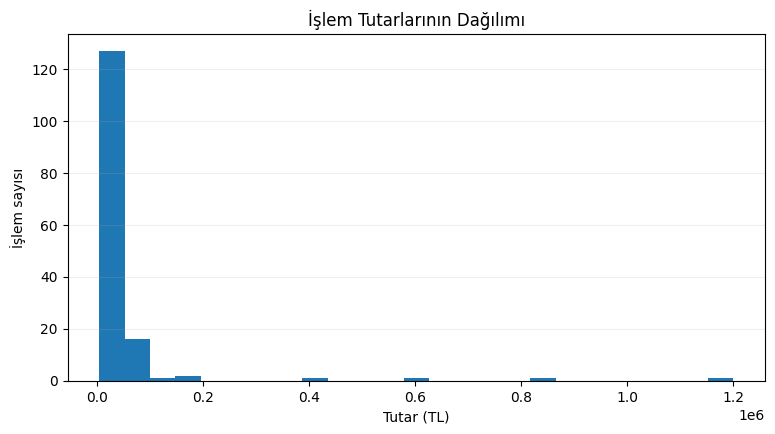

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4.5))
plt.hist(df["tutar"], bins=25)
plt.title("İşlem Tutarlarının Dağılımı")
plt.xlabel("Tutar (TL)")
plt.ylabel("İşlem sayısı")
plt.grid(axis="y", alpha=0.2)
plt.show()

### Grafiği nasıl okumalıyız?

Neredeyse tüm işlemler **en soldaki bir-iki çubukta** toplanmış; sağda ise birbirinden uzak, tek tük çubuklar var. Bu, `describe()` çıktısında gördüğümüz sağa çarpıklığın görsel karşılığıdır.

Bir sorun var: 1,2 milyonluk tek işlem x eksenini o kadar genişletiyor ki, işlemlerin büyük çoğunluğunun dağılımı görünmez hale geliyor.

**Deneyin:**

- Aykırı değerleri dışarıda bırakarak çizin: `plt.hist(df.loc[df["tutar"] < 200_000, "tutar"], bins=25)`
- Ya da logaritmik eksen kullanın: `plt.hist(df["tutar"], bins=25)` satırından sonra `plt.xscale("log")` ekleyin.

## 11. Outlier detection — IQR yöntemi

Aykırı değer, diğer gözlemlerden belirgin biçimde uzak duran değerdir. **Aykırı = hata veya hile demek değildir.** Denetim açısından anlamı: “Bu kayıt neden farklı?” sorusunu sormaya değer olabilir.

IQR (Interquartile Range — çeyrekler açıklığı) yöntemi:

- Q1 = %25 çeyreği
- Q3 = %75 çeyreği
- IQR = Q3 − Q1 → verinin **ortadaki %50'sinin** genişliği
- Alt sınır = Q1 − 1,5 × IQR
- Üst sınır = Q3 + 1,5 × IQR

Bu sınırların dışında kalan değerler aykırı kabul edilir.

### Neden IQR?

- **Dayanıklıdır:** Ortalama ve standart sapma, aykırı değerlerin kendisinden etkilenir. Çeyrekler ise birkaç uç değerden neredeyse hiç etkilenmez.
- **1,5 katsayısı** bir gelenektir (John Tukey). Daha az alarm isterseniz 3 kullanabilirsiniz (“uç aykırı değer”). Katsayı, denetim amacına göre ayarlanabilir ve gerekçesi kaydedilmelidir.

In [30]:
q1 = df["tutar"].quantile(0.25)
q3 = df["tutar"].quantile(0.75)
iqr = q3 - q1

alt_sinir = q1 - 1.5 * iqr
ust_sinir = q3 + 1.5 * iqr

print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Üst sınır:", round(ust_sinir, 2))

Q1: 16224.82
Q3: 43777.92
IQR: 27553.11
Üst sınır: 85107.59


### Çıktıyı nasıl okumalıyız?

- Ortadaki %50'lik işlemler **≈ 16 bin ile ≈ 44 bin TL** arasında.
- **Üst sınır ≈ 85 bin TL.** Bunun üzerindeki işlemler aykırı sayılacak.
- Alt sınırı yazdırmadık, ama hesaplarsanız **negatif** (≈ −25 bin) çıkar. Tutarlar negatif olamayacağı için bu veride alt tarafta aykırı değer bulunamaz. Sağa çarpık parasal verilerde bu sık görülen bir durumdur.

### Aykırı kayıtları bulmak

Şimdi alt veya üst sınırın dışında kalan kayıtları işaretleyelim:

```python
(df["tutar"] < alt_sinir) | (df["tutar"] > ust_sinir)
```

`|` işareti “**veya**” anlamına gelir: İki koşuldan biri doğruysa kayıt aykırıdır. Sonuç `outlier_iqr` adında `True`/`False` değerli yeni bir kolon olarak saklanır; böylece bu bilgiyi sonraki analizlerde de kullanabiliriz.

In [31]:
df["outlier_iqr"] = (df["tutar"] < alt_sinir) | (df["tutar"] > ust_sinir)

outlierlar = df[df["outlier_iqr"]].sort_values("tutar", ascending=False)
print("Bulunan aykırı kayıt sayısı:", len(outlierlar))
outlierlar[["fatura_no", "tedarikci", "birim", "tutar", "risk_skoru"]].head(15)

Bulunan aykırı kayıt sayısı: 10


,fatura_no,tedarikci,birim,tutar,risk_skoru
140,FTR-1143,Nova Lojistik,Bilgi İşlem,1200000.00,25
111,FTR-1114,Başkent Temizlik,Bilgi İşlem,850000.00,25
52,FTR-1054,Kuzey Yazılım Ltd.,Mali İşler,610000.00,25
7,FTR-1008,Mavi Ofis Malzemeleri,İdari İşler,420000.00,45
139,FTR-1142,Kuzey Yazılım Ltd.,Mali İşler,180000.00,70
30,FTR-1031,Atlas Danışmanlık,Mali İşler,149241.05,25
138,FTR-1141,Kuzey Yazılım Ltd.,Mali İşler,132904.32,25
118,FTR-1121,Anadolu Gıda,Satın Alma,96898.87,25
57,FTR-1059,Kuzey Yazılım Ltd.,Mali İşler,88960.97,25
126,FTR-1129,Atlas Danışmanlık,Bilgi İşlem,86737.56,20


### Çıktıyı nasıl okumalıyız? — önemli bir karşılaştırma

**10 kayıt** aykırı bulundu. Şimdi `risk_skoru` kolonuna bakın:

- **FTR-1143 (1,2 milyon TL)** en büyük aykırı değer, ama risk skoru yalnızca **25**.
- **FTR-1142 (180 bin TL)** listede beşinci sırada, ama risk skoru **70** — veri setindeki en yüksek skor.

Neden? Çünkü iki yöntem **farklı sorulara** cevap veriyor:

| Yöntem | Sorduğu soru |
|---|---|
| IQR outlier | Bu işlemin **tutarı** diğerlerine göre olağandışı mı? |
| Risk skoru | Bu işlemde **birden fazla risk sinyali** bir arada mı? |

1,2 milyonluk işlemin onay süresi 10 gün, tek kaynak değil, IBAN'ı tam — skor açısından sadece “büyük”. Oysa önceki bölümde gördüğümüz gibi açıklaması “Kırtasiye alımı”; bu uyumsuzluk risk skorunun hiçbir kuralına takılmıyor. 180 binlik işlem ise büyük **ve** geç onaylanmış **ve** tek kaynak.

> **Denetim yorumu:** Hiçbir tek yöntem “en riskli” kaydı tek başına belirlemez. Farklı yöntemlerin sonuçlarını yan yana koymak, inceleme listesini daha sağlam yapar.

### Boxplot ile aykırı değerleri görmek

Boxplot (kutu grafiği), IQR yönteminin görsel karşılığıdır:

- **Kutu:** Q1'den Q3'e kadar — verinin ortadaki %50'si,
- **Kutunun içindeki çizgi:** Medyan,
- **Bıyıklar:** Kutudan 1,5 × IQR mesafeye kadar uzanan çizgiler (bu aralıktaki en uç değere kadar),
- **Tek tek noktalar:** Bıyıkların dışında kalan **aykırı değerler**.

Bu veride kutu sol tarafta çok dar kalacak, sağa doğru ise uzun bir aykırı nokta dizisi görülecek. Bu da sağa çarpık bir dağılımın tipik görüntüsüdür.

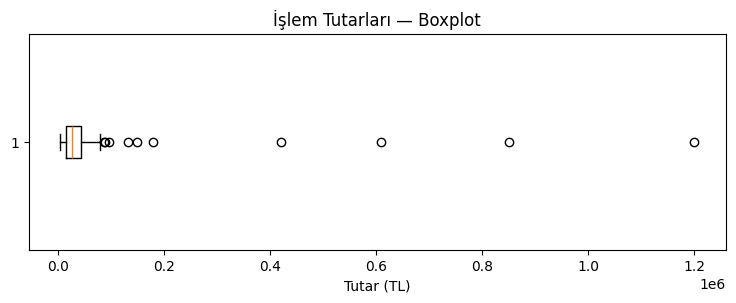

In [32]:
plt.figure(figsize=(9, 2.8))
plt.boxplot(df["tutar"], vert=False)
plt.title("İşlem Tutarları — Boxplot")
plt.xlabel("Tutar (TL)")
plt.show()

## 12. Fuzzy matching ile yaklaşık metin arama

Gerçek hayattaki denetim verilerinde aynı tedarikçi farklı biçimlerde yazılabilir:

- `ABC Teknoloji Ltd.`
- `ABC Teknoloji Ldt.`
- `Abc Teknoloji`

Tam eşleşme (`==`) bu kayıtları farklı kabul eder. **Fuzzy matching** (bulanık eşleştirme), iki metnin ne kadar benzediğini 0–100 arası bir puanla ölçerek yaklaşık eşleşme yapar.

### Denetimde neden önemli?

- **Limit bölme:** Aynı tedarikçiye yapılan alımlar farklı yazımlar nedeniyle ayrı tedarikçiler gibi görünürse, toplam alım tutarı ve ihale eşikleri yanlış hesaplanır.
- **Mükerrer kayıt:** Aynı firma tedarikçi listesinde iki kez kayıtlı olabilir.
- **Kara liste / ilişkili taraf kontrolü:** Bir listeyle karşılaştırırken küçük yazım farkları eşleşmeyi kaçırtır.

### FuzzyWuzzy ve RapidFuzz

Bu alanda uzun süre **FuzzyWuzzy** kütüphanesi kullanıldı. Bugün aynı fonksiyonları sunan, çok daha hızlı ve daha esnek lisanslı **RapidFuzz** tercih ediliyor. Mantık ve fonksiyon adları neredeyse aynıdır. Biz RapidFuzz kullanacağız.

Colab'da gerekirse:

```python
%pip install rapidfuzz
```

In [35]:
!pip install rapidfuzz

### Eşik kullanarak benzer tedarikçi adlarını seçmek

Aşağıdaki kodda yanlış yazılmış `"ABC Teknolji"` ifadesini, verideki benzersiz tedarikçi adları içinde arıyoruz.

| Kod | Anlamı |
|---|---|
| `df["tedarikci"].dropna().unique().tolist()` | Boşları at, her tedarikçi adını bir kez al, listeye çevir |
| `process.extract(aranan, liste, ...)` | Aranan ifadeyi listedeki her adla karşılaştır |
| `scorer=fuzz.WRatio` | Birkaç benzerlik ölçüsünü birleştiren genel amaçlı puanlama |
| `limit=5` | En benzer 5 sonucu getir |

Sonuç `(isim, benzerlik_puanı, listedeki_sıra)` biçiminde üçlülerden oluşur.

### Diğer puanlama türleri

- `fuzz.ratio` → Karakter karakter genel benzerlik
- `fuzz.partial_ratio` → Kısa metin uzun metnin **bir parçasıyla** eşleşiyor mu? (`"ABC"` ↔ `"ABC Teknoloji Ltd."`)
- `fuzz.token_sort_ratio` → Kelime **sırasını** önemsemez (`"Teknoloji ABC"` ↔ `"ABC Teknoloji"`)

Örneğin benzerlik puanı 70 ve üzerindekileri inceleme listesine alabiliriz. Buradaki eşik veriye göre ayarlanmalıdır.

In [36]:
from rapidfuzz import process, fuzz

benzersiz_tedarikciler = df["tedarikci"].dropna().unique().tolist()

aranan = "ABC Teknolji"

sonuclar = process.extract(
    aranan,
    benzersiz_tedarikciler,
    scorer=fuzz.WRatio,
    limit=5
)

sonuclar

[('ABC Teknoloji Ltd.', 85.5, 4),
 ('ABC Teknoloji Ldt.', 85.5, 7),
 ('ABC Teknoloji LTD', 82.75862068965517, 10),
 ('Abc Teknoloji', 80.0, 9),
 ('Başkent Temizlik', 42.85714285714286, 5)]

### Çıktıyı nasıl okumalıyız?

| Sonuç | Puan |
|---|---|
| ABC Teknoloji Ltd. | 85,5 |
| ABC Teknoloji Ldt. | 85,5 |
| ABC Teknoloji LTD | 82,8 |
| Abc Teknoloji | 80,0 |
| Başkent Temizlik | 42,9 |

İlk dört sonuç aynı firmanın **dört farklı yazımı**. Beşinci sonuçla aralarında belirgin bir **puan uçurumu** var (80 → 43). Bu uçurum eşik seçmeyi kolaylaştırır: 70 eşiği, gerçek eşleşmeleri alıp alakasız olanı dışarıda bırakıyor.

> **Denetim yorumu:** Aynı tedarikçinin dört farklı yazımla kayıtlı olması başlı başına bir **ana veri (master data) kalitesi bulgusudur.** Bir sonraki adım, bu yazımları tek bir standart ada eşleyip (`df["tedarikci"].replace({...})`) tedarikçi bazlı toplamları yeniden hesaplamaktır. Toplam alım tutarı değişirse, ihale eşiği veya limit bölme analizi de değişebilir.

> **Uyarı:** Fuzzy matching bir **öneri** üretir, karar vermez. Benzer isimli iki firma gerçekten farklı tüzel kişiler olabilir. Vergi numarası, IBAN veya adres gibi ikinci bir alanla doğrulama yapılmalıdır.

## 13. Hazır EDA kütüphaneleri

Elle yaptığımız `head()`, `describe()`, eksik değer, dağılım ve korelasyon kontrollerini otomatikleştiren kütüphaneler vardır. Bunlar analistin yerini almaz; ilk keşfi hızlandırır.

Bu araçlar tek komutla şunları üretir: her kolonun özeti, dağılım grafikleri, eksik değer haritası, kolonlar arası korelasyonlar ve olası veri kalitesi uyarıları (sabit kolon, yüksek oranda eksik veri, tekrar eden satırlar vb.).

### YData Profiling

Tek komutla kapsamlı HTML/Notebook profili üretir.

```python
%pip install -q ydata-profiling
from ydata_profiling import ProfileReport
profil = ProfileReport(df, title="Denetim Verisi Profili", explorative=True)
profil.to_notebook_iframe()
```

> Not: `ydata-profiling` paketinin yeni sürümlerinde kütüphanenin adının değiştiğine dair bir uyarı görülebilir. Uyarı raporun üretilmesini engellemez.

### Sweetviz

Özellikle hızlı görsel EDA raporları için kullanılabilir. Rapor ayrı bir HTML dosyası olarak kaydedilir; bu klasördeki `eda_raporu.html` dosyası bu şekilde üretilmiştir.

```python
%pip install -q sweetviz
import sweetviz as sv
rapor = sv.analyze(df)
rapor.show_html("eda_raporu.html")
```

### Skimpy

Daha hafif, hızlı veri özeti ve veri temizleme yardımcıları sunar.

```python
%pip install -q skimpy
from skimpy import skim
skim(df)
```

> Eğitimde önerilen yaklaşım: Önce EDA'nın mantığını elle görmek, sonra otomatik EDA araçlarını hızlandırıcı olarak kullanmak. Otomatik rapor “neye bakmalıyım?” sorusuna ipucu verir; “bu ne anlama geliyor?” sorusunu yine denetçi cevaplar.

> **Veri güvenliği:** Bu kütüphaneler yerel olarak çalışır, ama üretilen HTML raporu verinin örnek satırlarını içerebilir. Gerçek denetim verisiyle üretilen raporları paylaşırken dikkatli olun.

### Opsiyonel uygulama: otomatik EDA raporu

Aşağıdaki iki hücre yorum satırı (`#`) olarak bırakılmıştır; çalıştırıldığında hiçbir şey yapmaz. Denemek isterseniz satır başlarındaki `#` işaretlerini kaldırın.

- Kurulum ve rapor üretimi internet bağlantısına ve veri boyutuna göre birkaç dakika sürebilir.
- Rapor üretildikten sonra notebook dosyasının boyutu belirgin biçimde büyüyebilir.

In [42]:
# %pip install -q ydata-profiling
# from ydata_profiling import ProfileReport
# profil = ProfileReport(df, title="Denetim Verisi Profili", explorative=True)
# profil.to_notebook_iframe()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.5 MB/s eta 0:00:00


/tmp/ipykernel_2239/2367066310.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 32.05it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [41]:
# %pip install -q sweetviz
# import sweetviz as sv
# rapor = sv.analyze(df)
# rapor.show_html("eda_raporu.html")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 86.4 MB/s eta 0:00:00


                                             |          | [  0%]   00:00 -> (? left)

Report eda_raporu.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


*Opsiyonel uygulama sonu.*

## 14. Zaman kalırsa — Duplicate kontrolü

Aynı fatura numarasının veya aynı fatura + tutar kombinasyonunun birden fazla kez geçmesi, incelenmesi gereken bir veri kalitesi veya **mükerrer ödeme** sinyali olabilir.

### Kod ne yapıyor?

```python
df.duplicated(subset=["fatura_no", "tutar"], keep=False)
```

- `subset=[...]` → Hangi kolonların **birlikte** aynı olması gerektiğini belirler. Burada hem fatura numarası hem tutar aynı olan kayıtları arıyoruz.
- `keep=False` → Tekrarlayan grubun **tüm** üyelerini işaretler. (Varsayılan `keep="first"` ilk kaydı “orijinal” sayıp işaretlemez; denetimde ikisini de görmek isteriz.)

### `subset` seçimi bir denetim kararıdır

| Kontrol | `subset` | Yakaladığı durum |
|---|---|---|
| Sıkı | `["fatura_no", "tedarikci", "tutar"]` | Birebir aynı faturanın iki kez girilmesi |
| Orta | `["fatura_no", "tutar"]` | Aynı fatura farklı tedarikçi koduna girilmiş olabilir |
| Geniş | `["tedarikci", "tutar", "tarih"]` | Farklı numarayla aynı ödemenin tekrarı |

Gerçek mükerrer ödeme testlerinde bu kontroller genellikle birlikte, farklı genişliklerde çalıştırılır.

In [40]:
duplicate_kayitlar = df[df.duplicated(subset=["fatura_no", "tutar"], keep=False)]
duplicate_kayitlar[["islem_id", "fatura_no", "tedarikci", "tutar", "tarih"]].sort_values("fatura_no")

,islem_id,fatura_no,tedarikci,tutar,tarih
74,75,FTR-1076,Kuzey Yazılım Ltd.,30150.01,2026-04-02
75,76,FTR-1076,Atlas Danışmanlık,30150.01,2026-03-04


### Çıktıyı nasıl okumalıyız?

**FTR-1076** numaralı fatura, aynı tutarla (30.150,01 TL) iki kez geçiyor. Ama:

- Tedarikçiler **farklı**: Kuzey Yazılım Ltd. ve Atlas Danışmanlık,
- Tarihler **farklı**: 4 Mart ve 2 Nisan 2026.

Öte yandan açıklama (“Bakım hizmeti”), birim ve onay süresi (28 gün) **aynı**; buna karşılık **IBAN'lar farklı**, yani ödeme iki ayrı hesaba gitmiş görünüyor.

Kuruşuna kadar aynı tutar ve aynı fatura numarasının iki farklı firmada tesadüfen oluşması çok düşük bir ihtimaldir. Olası açıklamalar:

1. **Veri girişi hatası:** Kayıtlardan birinde fatura numarası veya tedarikçi yanlış girilmiş.
2. **Mükerrer ödeme:** Aynı fatura iki kez, farklı tedarikçi kodlarıyla ödenmiş.

Hangisinin doğru olduğunu veri söyleyemez; **belgeye dönmek** gerekir. (Bir sonraki bölümde bu kayda dair ilginç bir ipucu daha çıkacak.)

## 15. Zaman kalırsa — Sıra / gap kontrolü

Sıralı numaralarda beklenmeyen boşluklar, iptal edilmiş kayıtları, veri aktarım sorunlarını veya incelenmesi gereken başka durumları gösterebilir.

Örnek veri setindeki `fatura_no` değerlerinin sayısal kısmını çıkarıp eksik numaraları arayalım.

### Kod adım adım

1. `.str.replace("FTR-", "")` → `"FTR-1041"` metninden `"1041"` kısmını bırakır,
2. `.astype(int)` → metni sayıya çevirir,
3. `.sort_values().unique()` → sıralar ve tekrarları atar,
4. `set(range(min, max + 1))` → en küçük ile en büyük numara arasında **olması gereken** tüm numaraları üretir,
5. `beklenen - mevcut` → küme farkı: olması gerekip de **olmayan** numaralar.

Bu, “önce ne olmalıydı listesini kur, sonra eldekiyle karşılaştır” mantığıdır — tarih kesintisi analizinde de aynı yaklaşım kullanılır.

In [39]:
fatura_sayilari = (
    df["fatura_no"]
      .str.replace("FTR-", "", regex=False)
      .astype(int)
      .sort_values()
      .unique()
)

beklenen = set(range(fatura_sayilari.min(), fatura_sayilari.max() + 1))
mevcut = set(fatura_sayilari)
eksik_numaralar = sorted(beklenen - mevcut)

print("Eksik fatura sıra numaraları:", eksik_numaralar)

Eksik fatura sıra numaraları: [1041, 1077, 1092]


### Çıktıyı nasıl okumalıyız?

**3 fatura numarası eksik: 1041, 1077 ve 1092.**

Her eksik numara için sorulacak soru: Bu numara **iptal edilmiş** mi (iptal kaydı ve gerekçesi var mı?), yoksa kayıt **sisteme hiç aktarılmamış** mı?

Şimdi bir önceki bölümle bağlantı kurun: **FTR-1076** iki kez geçiyordu ve hemen ardından gelen **FTR-1077 eksik.** Bu, kayıtlardan birinin aslında FTR-1077 olması gerekirken yanlışlıkla 1076 olarak girildiği ihtimalini güçlendirir.

> **Ders:** Tek başına zayıf görünen iki sinyal (bir mükerrer + bir boşluk) **yan yana konduğunda** çok daha anlamlı bir hipotez üretir. Denetim analitiğinde testleri birbirinden kopuk değil, birlikte okumak gerekir.

### Ek konu (eğitmen notu): `missingno` ile eksik veriyi görselleştirmek ⏰

Zaman kalırsa, eksik değerleri sayı yerine **görsel** olarak göstermek için `missingno` kütüphanesi tanıtılabilir:

```python
%pip install -q missingno
import missingno as msno

msno.matrix(df)   # Her satır bir kayıt; beyaz boşluklar eksik değerler
msno.bar(df)      # Kolon başına dolu değer oranı
```

`msno.matrix` özellikle eksikliklerin **rastgele mi yoksa bir örüntüyle mi** oluştuğunu görmek için kullanışlıdır. Örneğin eksik açıklamalar belirli bir tarih aralığında toplanıyorsa, bu bir sistem değişikliğine veya belirli bir dönemdeki uygulama zaafına işaret edebilir.

## 16. Mini alıştırmalar

Bu bölümde kodu doğrudan vermek yerine denetim sorusunu koda çevirmeyi deneyin:

1. Sadece **Mali İşler** birimine ait kayıtları filtreleyin.
2. Tutarı 100.000 TL'den büyük **ve** tek kaynak olan işlemleri bulun.
3. Her birimin toplam risk skorunu hesaplayın.
4. En yüksek risk skoruna sahip ilk 10 kaydı listeleyin.
5. `"Delta Insaat"` ifadesini fuzzy matching ile aratın.

<details>
<summary><b>İpuçları (önce kendiniz deneyin)</b></summary>

1. Filtreleme bölümündeki `df[df["kolon"] == "değer"]` kalıbını kullanın.
2. İki koşulu `&` ile bağlayın ve her koşulu paranteze alın. Tek kaynak bilgisinin `"E"` olarak kodlandığını unutmayın.
3. `groupby("birim")["risk_skoru"].sum()`
4. `sort_values(..., ascending=False).head(10)` veya `df.nlargest(10, "risk_skoru")`
5. Bölüm 12'deki `process.extract` kodunda yalnızca `aranan` değişkenini değiştirin. Verideki adın `"Delta İnşaat A.Ş."` olduğunu ve Türkçe karakter farkına rağmen eşleşip eşleşmediğini gözlemleyin.

</details>

Aşağıdaki hücreyi çalışma alanı olarak kullanabilirsiniz.

In [ ]:
# Çalışma alanı
# Örnek başlangıç:
# df[df["birim"] == "Mali İşler"]

## 17. Bu notebook'tan sonra ne geliyor?

Bu oturumda şu zihinsel modeli kurduk:

**Denetim sorusu → veri → filtre/kural → bulgu adayı → denetçi yorumu**

Son iki adım arasındaki fark önemlidir: Kod bir **bulgu adayı** üretir; onu **bulguya** çeviren, denetçinin belge incelemesi ve muhakemesidir.

İç denetime verilen iki günlük programın devamında bu yapı daha ileri tekniklere taşınabilir:

- IQR yanında Z-score ve çok değişkenli anomali yaklaşımları (ör. Mahalanobis uzaklığı)
- Örnekleme yöntemleri: rastgele, tabakalı ve tutarla orantılı (PPS)
- Benford Yasası ve kullanım sınırları
- Gap / sequence testlerinin genişletilmesi
- Generative AI ile kod üretme, açıklama ve hata ayıklama
- İlişkili tarafları bulmak için network analysis

> Yapay zekâ kodu hızlandırabilir; fakat **denetim sorusunu, doğru veri kolonunu ve bulgunun anlamını** hâlâ denetçinin belirlemesi gerekir.

## 18. Kapanış kontrolü

Notebook'u bitirdiğinizde şu soruların cevabını verebiliyor olmalısınız:

- Kod hücresi ile Markdown hücresi arasındaki fark nedir?
- Pandas DataFrame nedir?
- Excel dosyası nasıl okunur?
- Bir kolon nasıl seçilir ve filtrelenir?
- Birden fazla satıra aynı işlem nasıl uygulanır?
- Basit bir risk skoru nasıl kurulur?
- Çarpık parasal verilerde neden ortalama yerine medyan raporlanır?
- Outlier neden otomatik olarak “hile” anlamına gelmez?
- Risk skoru ile IQR outlier analizi neden farklı kayıtları öne çıkarabilir?
- Fuzzy matching hangi veri kalitesi sorununu çözmeye yardımcı olur?

Bu soruların çoğuna cevap verebiliyorsanız, artık ileri denetim analitiği teknikleri için gerekli temel hazırdır.